# Phase I · Hypothesis 2: Word clusters and model behaviour

Lukas showed in hypothesis 1 how much the irony score depends on `#irony`, `#sarcasm` and `#not`. This notebook looks at the rest of the text.

**Hypothesis:** The model treats certain words or topics as an irony signal. In groups of tweets with those words, the mean irony score should then be clearly higher or lower than the share of tweets that really are ironic.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from huggingface_hub import snapshot_download
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from transformers import AutoModelForSequenceClassification, AutoTokenizer

MODEL_ID = "cardiffnlp/twitter-roberta-base-irony"
MODEL_REVISION = "3bf8f118bdf6b00c99658151ef10c9a0b9afd6bf"

# show the full tweet text in tables
pd.set_option("display.max_colwidth", None)

## 1. Data and scores

In [2]:
tweets = load_dataset("cardiffnlp/tweet_eval", "irony", split="test").to_pandas()
print(tweets.shape)
tweets.head()

(784, 2)


,text,label
0,@user Can U Help?||More conservatives needed on #TSU + get paid 4 posting stuff like this!||YOU $ can go to,0
1,"Just walked in to #Starbucks and asked for a ""tall blonde"" Hahahaha #irony",1
2,#NOT GONNA WIN,0
3,@user He is exactly that sort of person. Weirdo!,0
4,So much #sarcasm at work mate 10/10 #boring 100% #dead mate full on #shit absolutely #sleeping mate can't handle the #sarcasm,1


Loading and scoring are taken from Lukas' notebook, so both hypotheses use the same scores.

In [3]:
checkpoint = snapshot_download(
    MODEL_ID,
    revision=MODEL_REVISION,
    allow_patterns=["config.json", "pytorch_model.bin", "merges.txt",
                    "vocab.json", "special_tokens_map.json"],
)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)
model.eval()


def normalize_tweet(text):
    tokens = []
    for token in text.split():
        if token.startswith("@") and len(token) > 1:
            token = "@user"
        elif token.startswith("http"):
            token = "http"
        tokens.append(token)
    return " ".join(tokens)


@torch.inference_mode()
def irony_scores(texts, batch_size=16):
    scores = []
    for start in range(0, len(texts), batch_size):
        batch = [normalize_tweet(text) for text in texts[start:start + batch_size]]
        inputs = tokenizer(batch, padding=True, truncation=True,
                           max_length=512, return_tensors="pt")
        logits = model(**inputs).logits
        scores.extend(logits.softmax(dim=-1)[:, 1].tolist())
    return scores

In [4]:
tweets["score"] = irony_scores(tweets["text"].tolist())
tweets["prediction"] = (tweets["score"] >= 0.5).astype(int)

tweets.head()

,text,label,score,prediction
0,@user Can U Help?||More conservatives needed on #TSU + get paid 4 posting stuff like this!||YOU $ can go to,0,0.303482,0
1,"Just walked in to #Starbucks and asked for a ""tall blonde"" Hahahaha #irony",1,0.649670,1
2,#NOT GONNA WIN,0,0.032981,0
3,@user He is exactly that sort of person. Weirdo!,0,0.209184,0
4,So much #sarcasm at work mate 10/10 #boring 100% #dead mate full on #shit absolutely #sleeping mate can't handle the #sarcasm,1,0.074537,0


## 2. Four groups

In [5]:
ironic = tweets["label"] == 1
predicted_ironic = tweets["prediction"] == 1

tweets.loc[ironic & predicted_ironic, "group"] = "true ironic"
tweets.loc[~ironic & ~predicted_ironic, "group"] = "true non-ironic"
tweets.loc[~ironic & predicted_ironic, "group"] = "false ironic"
tweets.loc[ironic & ~predicted_ironic, "group"] = "false non-ironic"

tweets["error"] = tweets["label"] != tweets["prediction"]

print("Accuracy:", round(1 - tweets["error"].mean(), 3))
tweets["group"].value_counts()

Accuracy: 0.735


group
true non-ironic     401
true ironic         175
false non-ironic    136
false ironic         72
Name: count, dtype: int64

The groups differ a lot in size. *False ironic* has only 72 tweets, so its word counts need care. The model also misses irony (136) almost twice as often as it wrongly detects it (72).

## 3. Frequent words per group

`#irony`, `#sarcasm` and `#not` are removed before counting. Every ironic tweet in the test split has at least one of them, so they would top every list, and they are already covered by hypothesis 1. The scores still come from the original text.

`user` is the placeholder for mentions (`@user`). It stays in because it marks replies.

In [6]:
tags = re.compile(r"(?<!\w)#(?:irony|sarcasm|not)\b", re.IGNORECASE)
tweets["clean_text"] = tweets["text"].str.replace(tags, "", regex=True)

count_vectorizer = CountVectorizer(stop_words="english", min_df=3)
counts = count_vectorizer.fit_transform(tweets["clean_text"])
words = count_vectorizer.get_feature_names_out()

counts.shape  # tweets x words

(784, 393)

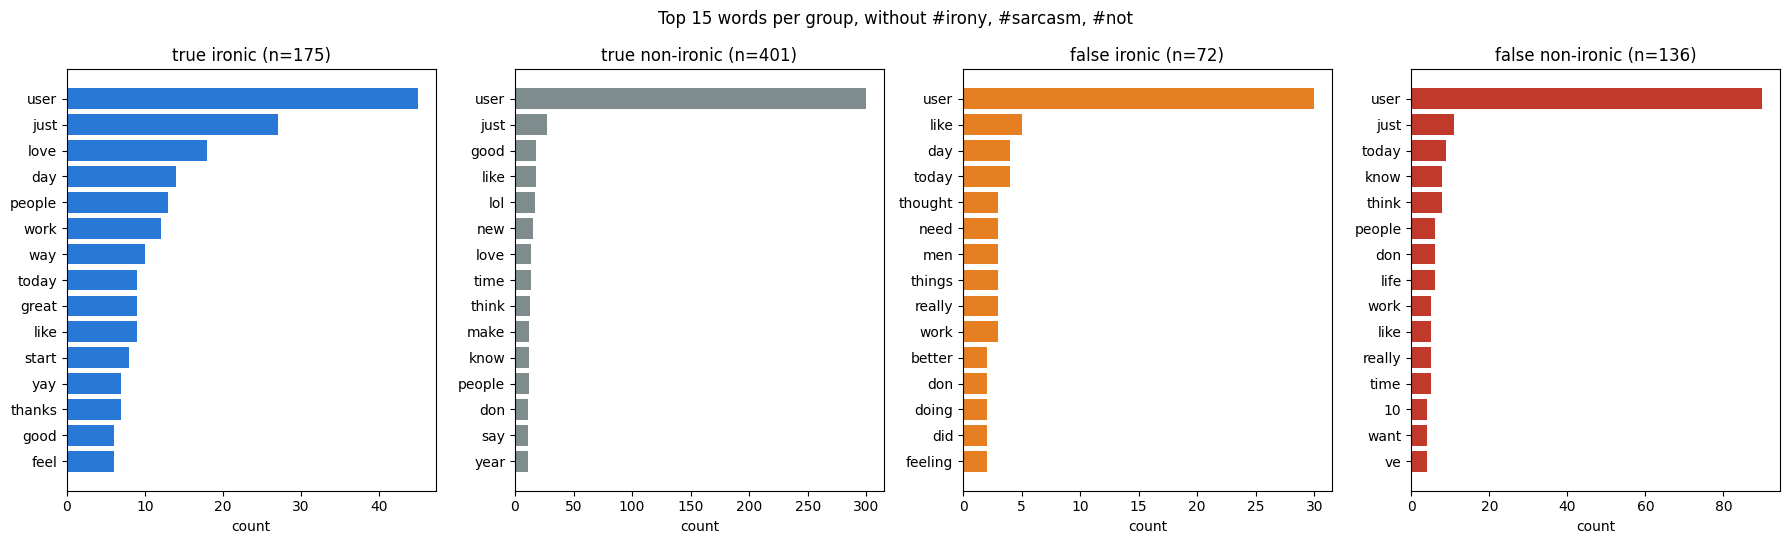

In [7]:
groups = ["true ironic", "true non-ironic", "false ironic", "false non-ironic"]
colors = ["#2a78d6", "#7f8c8d", "#e67e22", "#c0392b"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5.5))

for i in range(4):
    in_group = (tweets["group"] == groups[i]).to_numpy()
    totals = counts[in_group].sum(axis=0).A1   # one total per word
    top = totals.argsort()[-15:]               # 15 largest, ascending

    axes[i].barh(words[top], totals[top], color=colors[i])
    axes[i].set_title(f"{groups[i]} (n={in_group.sum()})")
    axes[i].set_xlabel("count")

fig.suptitle("Top 15 words per group, without #irony, #sarcasm, #not")
fig.tight_layout()
plt.show()

The groups have different sizes, so raw counts are hard to compare. The table shows the share of tweets (in %) that contain a word.

In [8]:
contains_word = pd.DataFrame(counts.toarray() > 0, columns=words)
share = contains_word.groupby(tweets["group"]).mean().T * 100

check = ["user", "just", "love", "day", "today", "great", "work", "lol", "good", "new"]
share.loc[check, groups].round(1)

group,true ironic,true non-ironic,false ironic,false non-ironic
user,17.1,45.9,33.3,38.2
just,14.9,6.7,2.8,8.1
love,10.3,3.2,2.8,2.9
day,8.0,2.2,4.2,2.9
today,5.1,1.5,5.6,6.6
great,5.1,1.2,0.0,0.7
work,6.9,1.2,4.2,3.7
lol,1.7,4.2,1.4,1.5
good,2.9,4.2,2.8,2.9
new,0.6,3.2,2.8,1.5


* `user` is in 46 % of the true non-ironic tweets but only 17 % of the true ironic ones. Replies are rarely ironic in this data, and the model follows that.
* `love`, `day`, `great` and `just` are most common in the true ironic group: positive words about everyday things.
* No word stands out in the two error groups. In *false ironic* the counts are 3 to 5, too few to say anything.

## 4. Clusters

TF-IDF with the same parameters, then K-Means. The typical words of a cluster are the columns with the highest values in its centre.

`n_init=10` lets K-Means try ten starting points and keep the best. With a single start, almost all tweets ended up in one cluster and several clusters had one tweet.

In [9]:
tfidf_vectorizer = TfidfVectorizer(stop_words="english", min_df=3)
tfidf = tfidf_vectorizer.fit_transform(tweets["clean_text"])
tfidf_words = tfidf_vectorizer.get_feature_names_out()

for k in [4, 6, 8]:
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels = kmeans.fit_predict(tfidf)

    print(k, "clusters")
    for c in range(k):
        top = kmeans.cluster_centers_[c].argsort()[::-1][:10]
        print(f"  {c}  n={(labels == c).sum():<4}", ", ".join(tfidf_words[top]))
    print()

4 clusters
  0  n=134  user, know, say, crime, tweet, wouldn, lol, racist, use, boy
  1  n=569  user, like, love, today, day, people, really, good, don, work
  2  n=20   time, christmas, user, sick, just, lol, got, mad, home, buy
  3  n=61   just, user, love, day, snow, final, people, christmas, think, need

6 clusters
  0  n=506  user, like, don, really, time, good, lol, people, christmas, work
  1  n=35   love, just, gotta, people, peace, oh, user, waking, makes, ve
  2  n=136  user, know, say, crime, tweet, wouldn, lol, racist, use, boy
  3  n=48   just, user, snow, need, wanna, article, closed, finals, people, final
  4  n=51   day, today, just, good, way, school, start, new, great, work
  5  n=8    wonder, true, anxiety, agree, person, make, woman, people, women, banks



8 clusters
  0  n=485  user, work, lol, good, day, know, think, start, ve, time
  1  n=35   love, just, gotta, peace, user, oh, people, night, waking, makes
  2  n=72   user, wouldn, time, needs, got, sure, business, let, racist, teacher
  3  n=34   really, want, didn, user, thanks, guess, lol, expect, long, ones
  4  n=44   like, christmas, user, just, feel, merry, look, think, ugly, years
  5  n=64   just, today, day, user, school, good, snow, going, need, wanna
  6  n=26   people, like, did, know, oh, today, user, don, calling, heart
  7  n=24   new, year, happy, user, today, thanks, dad, finished, tweeting, knowing



I use **6 clusters**. With 4, little is left besides the big rest cluster. With 6 there are readable groups: mentions (`user`), `love`, `just`, everyday life (`day`, `today`, `school`, `work`). With 8 these split into smaller clusters whose word lists look more random.

There is always one big rest cluster, because tweets are short and share few words. Only the smaller clusters can be interpreted.

In [10]:
kmeans = KMeans(n_clusters=6, random_state=0, n_init=10)
tweets["cluster"] = kmeans.fit_predict(tfidf)

cluster_words = []
for c in range(6):
    top = kmeans.cluster_centers_[c].argsort()[::-1][:5]
    cluster_words.append(", ".join(tfidf_words[top]))

cluster_words

['user, like, don, really, time',
 'love, just, gotta, people, peace',
 'user, know, say, crime, tweet',
 'just, user, snow, need, wanna',
 'day, today, just, good, way',
 'wonder, true, anxiety, agree, person']

## 5. Clusters vs. model behaviour

In [11]:
summary = tweets.groupby("cluster").agg(
    n=("text", "size"),
    mean_score=("score", "mean"),
    ironic_share=("label", "mean"),
    error_rate=("error", "mean"),
)
summary["gap"] = summary["mean_score"] - summary["ironic_share"]
summary["top_words"] = cluster_words

summary.round(3)

,n,mean_score,ironic_share,error_rate,gap,top_words
cluster,,,,,,
0,506,0.373,0.399,0.289,-0.027,"user, like, don, really, time"
1,35,0.545,0.571,0.143,-0.026,"love, just, gotta, people, peace"
2,136,0.212,0.228,0.199,-0.016,"user, know, say, crime, tweet"
3,48,0.396,0.500,0.229,-0.104,"just, user, snow, need, wanna"
4,51,0.518,0.647,0.333,-0.129,"day, today, just, good, way"
5,8,0.272,0.125,0.250,0.147,"wonder, true, anxiety, agree, person"


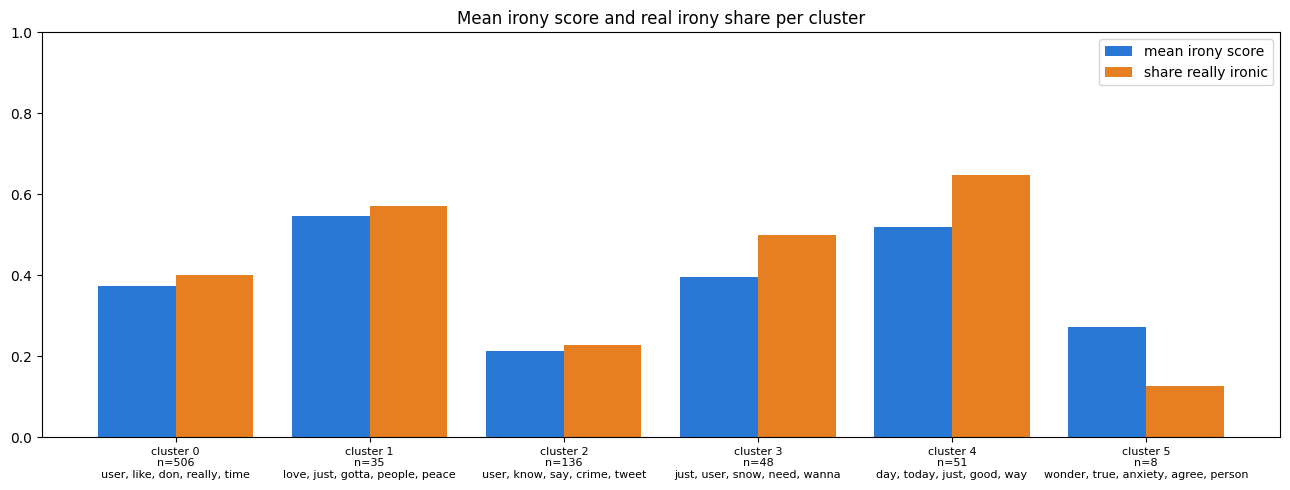

In [12]:
x = np.arange(6)
tick_labels = [f"cluster {c}\nn={summary['n'][c]}\n{cluster_words[c]}" for c in range(6)]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - 0.2, summary["mean_score"], width=0.4, label="mean irony score", color="#2a78d6")
ax.bar(x + 0.2, summary["ironic_share"], width=0.4, label="share really ironic", color="#e67e22")

ax.set_xticks(x)
ax.set_xticklabels(tick_labels, fontsize=8)
ax.set_ylim(0, 1)
ax.set_title("Mean irony score and real irony share per cluster")
ax.legend()
fig.tight_layout()
plt.show()